<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [X12 EDI](https://github.com/Query-farm/vgi-x12)

Inspect and edit healthcare and business interchanges without moving data off your machine.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-x12/blob/main/notebooks/02_escape_characters_change_fields_not_segment_counts.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-x12/blob/main/notebooks/README.md)


## A passing segment count can hide a changed field boundary

What does one missing release character do to a message? Compare two authored UN/EDIFACT examples differing only by `?` before a literal plus sign in FTX text. The real decoder returns their envelope and element rows. A correct count of segments does not establish that the text was divided into the intended fields.

Both messages are synthetic alternatives, not business transactions. Their party IDs, control references, date, time and free text are invented. We use public segment identifiers and positions only; raw codes are not translated through an implementation guide.

### Select one of two immutable alternatives

`ESCAPE_PLUS=True` selects the authored text `Subtotal 5?+ fee`; **False** selects `Subtotal 5+ fee`. Both complete inputs are decoded once, then the visible parameter selects local rows. The plus is intended as text in the first case; removing its release character makes it a separator under the declared syntax. This experiment changes no source file and repairs nothing.

In [1]:
ESCAPE_PLUS = True

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.20":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.20"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from decimal import Decimal
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("x12")
import x12_example as example

example.verify_fixtures()
example.validate_switch(ESCAPE_PLUS, "ESCAPE_PLUS")
con = connect(globals())
theme()

### Inspect the supplied syntax before interpreting returned positions

The scalar `delimiters` returns element, segment, component and repetition separators. It does not return a release-character column, so the `?` declaration is shown in the raw UNA prefix. `transaction_type` detects ORDERS for both files; the X12 shaped-reader reference has no ORDERS row. That is a projection-coverage distinction, not a rejection of EDIFACT parsing.

Read the pinned native release from the notebook directory alone. The setup verifies both fixture hashes. No live endpoint, real account or remote dataset is involved.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'x12' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-x12@v0.5.0');
CREATE TABLE sources AS SELECT filename AS source_path,
 regexp_extract(filename,'([^/]+)\.edi$',1) AS variant,content,
 sha256(content) AS text_sha256,x12.main.delimiters(content) AS syntax,
 x12.main.transaction_type(content) AS first_transaction_type
FROM read_text('fixtures/edifact/*.edi');
CREATE TABLE envelopes AS SELECT * FROM x12.main.edifact_envelope('fixtures/edifact/*.edi');
CREATE TABLE element_rows AS SELECT * FROM x12.main.edifact_segments('fixtures/edifact/*.edi');
CREATE TABLE selected_source AS SELECT * FROM sources
WHERE variant=CASE WHEN {{ESCAPE_PLUS}} THEN 'escaped' ELSE 'unescaped' END;

,Count


In [5]:
%%sql inventory <<
SELECT s.variant,length(content) AS supplied_characters,text_sha256,
 substr(content,1,9) AS una_prefix,syntax.element AS element_separator,
 syntax.segment AS segment_terminator,syntax.component AS component_separator,
 syntax.repetition AS repetition_separator,first_transaction_type,t.shaped_function
FROM sources s LEFT JOIN x12.main.transaction_sets t
 ON t.transaction_set=s.first_transaction_type ORDER BY variant;

In [6]:
display(inventory)
prose(f"Both **{len(inventory)} inputs** use the same returned separator tuple and ORDERS type; their hashes differ. Neither has a shaped X12 reader in this reference. We therefore inspect the dedicated EDIFACT envelope and element projections, without treating a missing reference match as invalid input.")

,variant,supplied_characters,text_sha256,una_prefix,element_separator,segment_terminator,component_separator,repetition_separator,first_transaction_type,shaped_function
0,escaped,149,8df32fbe9cdc3cc663f0152b3eef186d9fccdad7399c17...,UNA:+.? ',+,',:,None,ORDERS,None
1,unescaped,148,effa0699effe72d2ed447b5c1622db0f39991deef99aec...,UNA:+.? ',+,',:,None,ORDERS,None


Both **2 inputs** use the same returned separator tuple and ORDERS type; their hashes differ. Neither has a shaped X12 reader in this reference. We therefore inspect the dedicated EDIFACT envelope and element projections, without treating a missing reference match as invalid input.

### The envelope counts messages and segments, not element boundaries

Each file contains one UNH–UNT message with three segments. `unt_count_ok` compares that declared count with the parsed segment count. It is not a full EDIFACT validation result, does not prove all outer controls agree, and does not check the intended text boundary. The date/time fields are uninterpreted strings from authored headers, not a collection timestamp.

Both alternatives reuse the same control references. Keep source path in every join so the test cases do not cross-match.

In [7]:
%%sql envelope_audit <<
SELECT s.variant,e.interchange_ctrl,e.transaction_ctrl,e.transaction_type,
 e.message_version,e.message_release,e.segment_count,e.unt_count_ok,
 e.unb_date AS authored_date_code,e.unb_time AS authored_time_code
FROM envelopes e JOIN sources s USING(source_path) ORDER BY s.variant;

In [8]:
display(envelope_audit)
prose(f"**{int(envelope_audit.unt_count_ok.sum())} of {len(envelope_audit)} message rows** pass the UNT count check, each with **{int(envelope_audit.segment_count.iloc[0])} parsed segments**. That unchanged envelope result cannot tell whether the plus belongs inside a text element.")

,variant,interchange_ctrl,transaction_ctrl,transaction_type,message_version,message_release,segment_count,unt_count_ok,authored_date_code,authored_time_code
0,escaped,REF-DEMO,MSG-DEMO,ORDERS,D,96A,3,True,240101,1200
1,unescaped,REF-DEMO,MSG-DEMO,ORDERS,D,96A,3,True,240101,1200


**2 of 2 message rows** pass the UNT count check, each with **3 parsed segments**. That unchanged envelope result cannot tell whether the plus belongs inside a text element.

### Follow the selected FTX field positions

`edifact_segments` emits one row per element or component inside the UNH–UNT message. Empty positions are empty strings, not NULL and not missing rows. The selected FTX text table preserves them explicitly. No integer or monetary meaning is inferred from the digit in this arbitrary text.

The chart counts decoded element/component rows by segment. UNH has a composite element and therefore more rows than top-level element positions. These counts must not be called segment counts or message counts.

In [9]:
%%sql selected_fields <<
SELECT s.variant,e.segment_index,e.element_index,e.component_index,
 CASE WHEN e.value='' THEN '[empty string]' ELSE e.value END AS displayed_value,
 length(e.value) AS value_characters
FROM element_rows e JOIN selected_source s USING(source_path)
WHERE segment_id='FTX' ORDER BY e.element_index,e.component_index;

In [10]:
%%sql segment_counts <<
SELECT e.segment_index,e.segment_id,count(*) AS decoded_value_rows,
 count(DISTINCT e.element_index) AS top_level_positions,
 count(*) FILTER(WHERE e.value='') AS empty_value_rows
FROM element_rows e JOIN selected_source s USING(source_path)
GROUP BY ALL ORDER BY e.segment_index;

,variant,segment_index,element_index,component_index,displayed_value,value_characters
0,escaped,1,1,<NA>,AAA,3
1,escaped,1,2,<NA>,[empty string],0
2,escaped,1,3,<NA>,[empty string],0
3,escaped,1,4,<NA>,Subtotal 5+ fee,15


,segment_index,segment_id,decoded_value_rows,top_level_positions,empty_value_rows
0,0,UNH,5,2,0
1,1,FTX,4,4,2
2,2,UNT,2,2,0


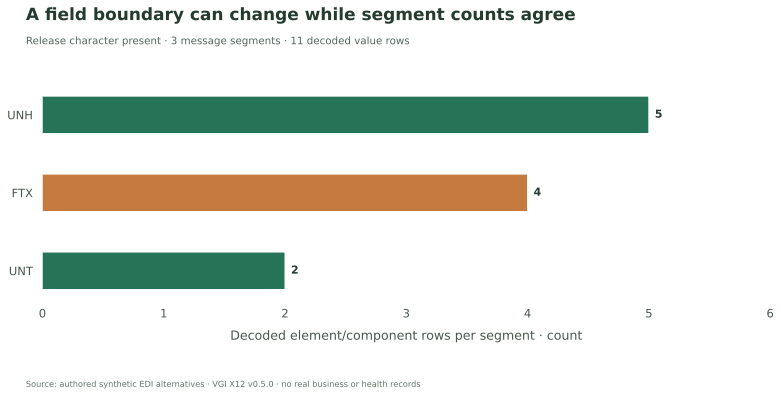

Selected FTX has **4 top-level positions**, including **2 empty strings**. Position 4 contains `Subtotal 5+ fee`. The whole selected message yields **11 element/component rows** while its segment count stays **3**. Boundary interpretation and envelope counts answer different questions.

In [11]:
display(selected_fields)
display(segment_counts)
example.edifact_counts(segment_counts, ESCAPE_PLUS)
ftx = segment_counts.loc[segment_counts.segment_id=='FTX'].iloc[0]
text4 = selected_fields.loc[selected_fields.element_index==4,'displayed_value'].iloc[0]
prose(f"Selected FTX has **{int(ftx.top_level_positions)} top-level positions**, including **{int(ftx.empty_value_rows)} empty strings**. Position 4 contains `{text4}`. The whole selected message yields **{int(segment_counts.decoded_value_rows.sum())} element/component rows** while its segment count stays **3**. Boundary interpretation and envelope counts answer different questions.")

### Reconcile the syntax experiment

These checks verify the two inputs differ by exactly the authored release character, retain both envelopes, preserve the fixed UNH/UNT values, and select one source without multiplying rows. They validate this example's decoding and scope, not business-rule compliance or every possible release-character combination.

In [12]:
%%sql checks <<
SELECT 'two immutable alternatives' AS check_name,count(*)=2 AS passed FROM sources
UNION ALL SELECT 'only the authored release character differs',
 (SELECT replace(content,'5?+','5+') FROM sources WHERE variant='escaped')=(SELECT content FROM sources WHERE variant='unescaped')
UNION ALL SELECT 'both envelope counts pass',count(*)=2 AND bool_and(unt_count_ok AND segment_count=3) FROM envelopes
UNION ALL SELECT 'selected source is unique',count(*)=1 FROM selected_source
UNION ALL SELECT 'selected message has three segment identities',count(DISTINCT e.segment_index)=3 FROM element_rows e JOIN selected_source s USING(source_path)
UNION ALL SELECT 'FTX empty positions remain explicit',count(*)=2 AND bool_and(value='') FROM element_rows e JOIN selected_source s USING(source_path) WHERE segment_id='FTX' AND element_index IN(2,3)
UNION ALL SELECT 'FTX field count follows the selected syntax',count(*)=CASE WHEN {{ESCAPE_PLUS}} THEN 4 ELSE 5 END FROM element_rows e JOIN selected_source s USING(source_path) WHERE segment_id='FTX'
UNION ALL SELECT 'escaped text retains literal plus',value='Subtotal 5+ fee' FROM element_rows e JOIN sources s USING(source_path) WHERE variant='escaped' AND segment_id='FTX' AND element_index=4
UNION ALL SELECT 'unescaped separator creates a fifth field',value=' fee' FROM element_rows e JOIN sources s USING(source_path) WHERE variant='unescaped' AND segment_id='FTX' AND element_index=5
UNION ALL SELECT 'control segment values stay unchanged',NOT EXISTS(
 (SELECT segment_index,segment_id,element_index,component_index,value FROM element_rows e JOIN sources s USING(source_path) WHERE variant='escaped' AND segment_id<>'FTX'
 EXCEPT ALL SELECT segment_index,segment_id,element_index,component_index,value FROM element_rows e JOIN sources s USING(source_path) WHERE variant='unescaped' AND segment_id<>'FTX'));

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"All **{len(checks)} SQL checks** pass. The authored missing release character changes a field boundary without changing the three-segment envelope count; the empty fields and fixed control values remain visible.")

,check_name,passed
0,two immutable alternatives,True
1,only the authored release character differs,True
2,both envelope counts pass,True
3,selected source is unique,True
4,selected message has three segment identities,True
5,FTX empty positions remain explicit,True
6,FTX field count follows the selected syntax,True
7,escaped text retains literal plus,True
8,unescaped separator creates a fifth field,True
9,control segment values stay unchanged,True


All **10 SQL checks** pass. The authored missing release character changes a field boundary without changing the three-segment envelope count; the empty fields and fixed control values remain visible.

### Try one change

Set only `ESCAPE_PLUS=False`, restart and run all into a separate experiment destination. Predict whether the UNT count check changes, then inspect FTX positions 4 and 5. The input inventory, both envelope rows and control-segment values must stay fixed. Restore **True** for the saved default. A passing count does not authorize accepting the altered message.

In [14]:
con.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-x12](https://github.com/Query-farm/vgi-x12)